In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

os.makedirs("../submission", exist_ok=True)

df = pd.read_csv("../data/demanda_comercial.csv.zip", compression="zip")
df["Fecha"] = pd.to_datetime(df["Fecha"])
df = df.set_index("Fecha")
df.head()

,H01,H02,H03,H04,H05,H06,H07,H08,H09,H10,...,H15,H16,H17,H18,H19,H20,H21,H22,H23,H24
Fecha,,,,,,,,,,,,,,,,,,,,,
2017-01-01,6090271.96,5887031.28,5708693.89,5538133.02,5389774.53,5288199.94,4851217.85,4876162.18,5073813.27,5359713.29,...,5745568.87,5647807.40,5609297.84,5690105.56,6761038.26,7077861.59,6979468.90,6695312.12,6289107.72,5794545.98
2017-01-02,5557603.42,5361012.17,5239119.86,5163721.70,5249539.75,5438852.95,5566947.57,6055220.80,6588005.66,6979088.72,...,7610559.73,7584026.97,7421194.49,7317194.26,8182697.67,8482127.69,8251009.75,7836278.95,7221234.85,6660691.64
2017-01-03,6160676.02,5924880.04,5764416.93,5685832.28,5778222.13,5985840.29,6083907.36,6545100.21,7092804.54,7461185.94,...,8148614.93,8117168.00,7930900.03,7783762.28,8653467.38,8835882.88,8562448.23,8095841.79,7443299.51,6840297.15
2017-01-04,6321851.20,6092135.24,5905390.85,5827867.82,5925730.02,6182279.89,6276759.96,6737660.53,7256819.19,7608691.40,...,8164513.51,8132006.92,7962749.39,7841533.59,8700506.07,8860255.66,8611085.76,8147451.75,7471240.82,6838250.32
2017-01-05,6395397.96,6162409.22,6001153.67,5918673.26,6005924.21,6225027.53,6322923.78,6739120.44,7307847.42,7619827.03,...,8144209.65,8136193.07,8022918.36,7927405.07,8718181.89,8832234.87,8579992.47,8063978.64,7406615.66,6829864.57


In [2]:
df.isna().sum().sum(), df.shape

(0, (2069, 24))

In [3]:
df = df.dropna()
hours = list(range(1, 25))

plt.figure(figsize=(10, 5))
plt.plot(hours, df.T.values / 1e6, color="tab:blue", alpha=0.05, linewidth=0.8)
plt.xlabel("Hora del día")
plt.ylabel("Demanda (millones)")
plt.title("Demanda comercial horaria (todos los días)")
plt.xticks(hours)
plt.grid(color="lightgray", linestyle="--", linewidth=0.5)
plt.savefig("../submission/demanda-comercial.png", dpi=120, bbox_inches="tight")
plt.show()

<Figure size 1000x500 with 1 Axes>

In [4]:
# Each day is normalized by its own mean so that clustering groups
# days by the *shape* of the curve and not by its level.
profiles = df.div(df.mean(axis=1), axis=0)
profiles.head()

,H01,H02,H03,H04,H05,H06,H07,H08,H09,H10,...,H15,H16,H17,H18,H19,H20,H21,H22,H23,H24
Fecha,,,,,,,,,,,,,,,,,,,,,
2017-01-01,1.048525,1.013534,0.982831,0.953466,0.927924,0.910437,0.835204,0.839499,0.873527,0.922749,...,0.989179,0.972348,0.965718,0.979631,1.164007,1.218552,1.201612,1.152691,1.082757,0.997611
2017-01-02,0.814756,0.785935,0.768066,0.757012,0.769593,0.797347,0.816126,0.887708,0.965815,1.023149,...,1.115724,1.111834,1.087962,1.072716,1.199600,1.243497,1.209615,1.148815,1.058648,0.976471
2017-01-03,0.845901,0.813525,0.791492,0.780702,0.793388,0.821895,0.835360,0.898685,0.973889,1.024470,...,1.118858,1.114540,1.088965,1.068762,1.188178,1.213225,1.175680,1.111612,1.022014,0.939218
2017-01-04,0.856154,0.825045,0.799754,0.789255,0.802509,0.837253,0.850048,0.912467,0.982775,1.030428,...,1.105702,1.101300,1.078378,1.061962,1.178290,1.199925,1.166180,1.103392,1.011814,0.926089
2017-01-05,0.864924,0.833414,0.811606,0.800451,0.812251,0.841883,0.855123,0.911410,0.988325,1.030518,...,1.101436,1.100352,1.085033,1.072115,1.179061,1.194486,1.160372,1.090586,1.001683,0.923682


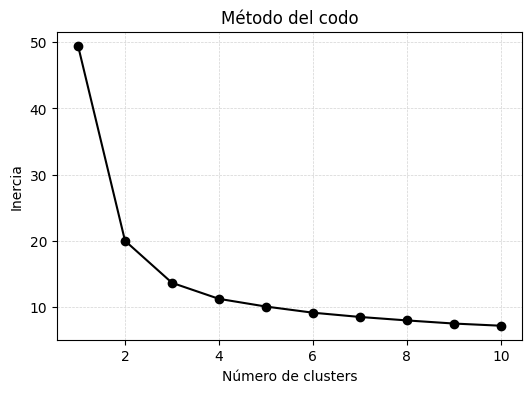

In [5]:
from sklearn.cluster import KMeans

inertias = []
k_values = range(1, 11)
for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(profiles)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(list(k_values), inertias, "o-k")
plt.xlabel("Número de clusters")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.grid(color="lightgray", linestyle="--", linewidth=0.5)
plt.show()

In [6]:
N_CLUSTERS = 4

kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=42)
df["cluster"] = kmeans.fit_predict(profiles)
df["cluster"].value_counts().sort_index()

cluster
0    422
1    662
2    317
3    668
Name: count, dtype: int64

In [7]:
# How clusters relate to the day of the week
pd.crosstab(df.index.day_name(), df["cluster"])

cluster,0,1,2,3
row_0,,,,
Friday,15,97,10,173
Monday,64,163,2,67
Saturday,16,0,276,3
Sunday,296,0,0,0
Thursday,11,129,10,145
Tuesday,10,139,8,139
Wednesday,10,134,11,141


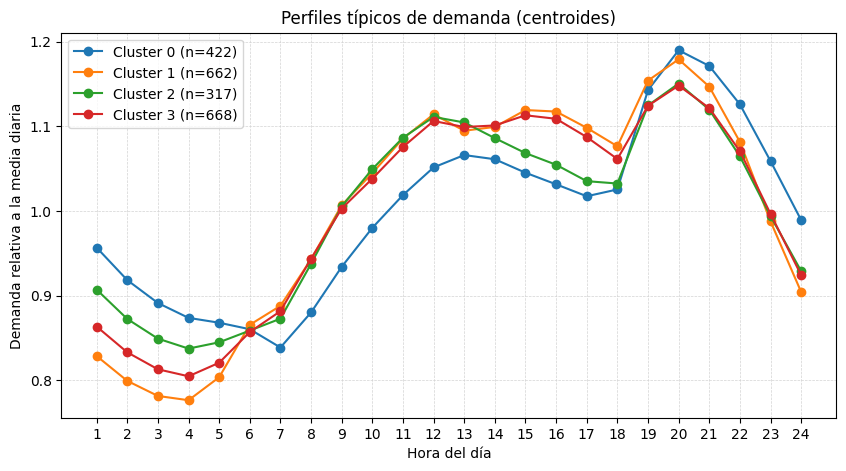

In [8]:
colors = plt.cm.tab10.colors

plt.figure(figsize=(10, 5))
for cluster, centroid in enumerate(kmeans.cluster_centers_):
    size = (df["cluster"] == cluster).sum()
    plt.plot(hours, centroid, "o-", color=colors[cluster], label=f"Cluster {cluster} (n={size})")
plt.xlabel("Hora del día")
plt.ylabel("Demanda relativa a la media diaria")
plt.title("Perfiles típicos de demanda (centroides)")
plt.xticks(hours)
plt.legend()
plt.grid(color="lightgray", linestyle="--", linewidth=0.5)
plt.savefig("../submission/demanda-comercial-perfiles.png", dpi=120, bbox_inches="tight")
plt.show()

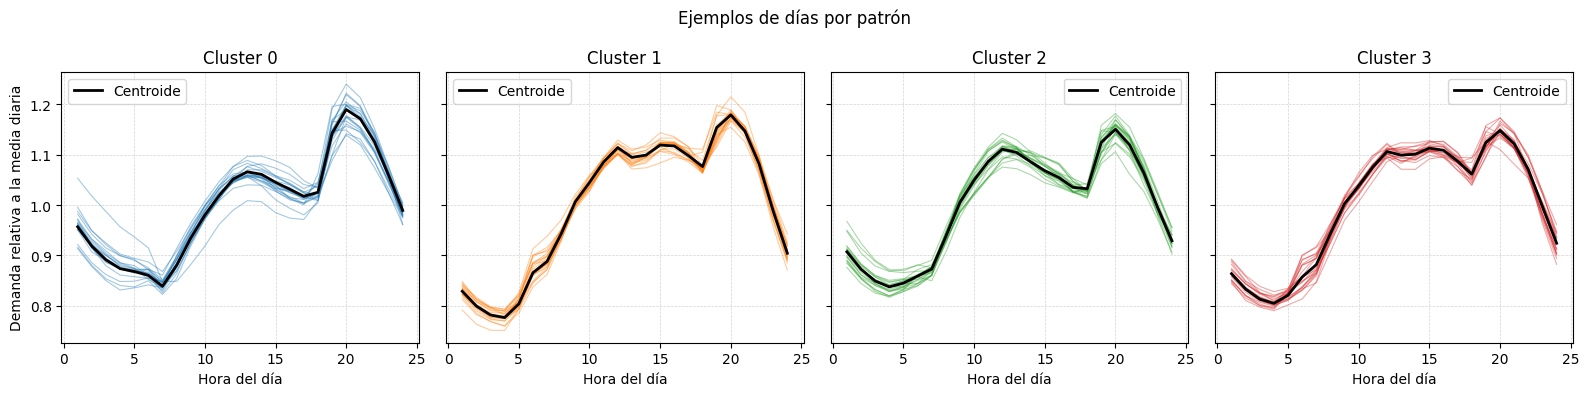

In [9]:
fig, axes = plt.subplots(1, N_CLUSTERS, figsize=(4 * N_CLUSTERS, 4), sharey=True)
for cluster, ax in enumerate(axes):
    members = profiles[df["cluster"] == cluster]
    examples = members.sample(n=min(20, len(members)), random_state=42)
    ax.plot(hours, examples.T.values, color=colors[cluster], alpha=0.4, linewidth=0.8)
    ax.plot(hours, kmeans.cluster_centers_[cluster], "k-", linewidth=2, label="Centroide")
    ax.set_title(f"Cluster {cluster}")
    ax.set_xlabel("Hora del día")
    ax.grid(color="lightgray", linestyle="--", linewidth=0.5)
    ax.legend()
axes[0].set_ylabel("Demanda relativa a la media diaria")
plt.suptitle("Ejemplos de días por patrón")
plt.tight_layout()
plt.savefig("../submission/demanda-comercial-patrones-ejemplo.png", dpi=120, bbox_inches="tight")
plt.show()